In [2]:
# required versions
#!python --version # 3.11.13
#!pip show qiskit # 2.3.0
#!pip show iqm-client # 33.0.4

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from iqm.qiskit_iqm.iqm_naive_move_pass import transpile_to_IQM
from fake_vlq import FakeVLQ
from numpy import pi
from qiskit import QuantumCircuit
from qiskit.circuit.library import RYGate, XGate, SwapGate, ZGate, HGate
from qiskit.circuit.library import Initialize

In [3]:
SHOTS = 10_000

In [4]:
backendFakeVLQ = FakeVLQ()

In [5]:
def prepare_basis_state(qc, bitstring):
    """
    Prepares |bitstring> using X gates only.
    """
    # Qiskit uses little-endian ordering in circuits:
    # bitstring = 'abcd' means q0=d, q1=c, q2=b, q3=a
    for i, bit in enumerate(reversed(bitstring)):
        if bit == '1':
            qc.x(i)

"""
theta = [ 0.17695402, -0.12298131, 1.12965455, 1.2893383,
          0.58636691, 0.75703076, 0.06989073, 1.61074935, 1.20699476, 0.46741536,
         -0.13104318, 1.19309581, 1.60774977, -0.21593251, 0.82947385, 0.71620414,
          0.34277525, 0.99030801, 0.10546242, -1.30964618, 0.07851207, 1.41351836,
          0.95826736, 0.83569138, 0.34291868, 1.03396337, 0.31886943, -0.24984994,
          1.43633764, 0.79437362, 0.4391148 , 1.16457483, -0.00312721, 1.22338627,
          0.34434453, -0.39312237, 1.00542707, 0.50120635, 1.63337712, 1.26461392,
          0.46973431, 0.71563605, -0.66516074, 1.02825479, 0.41318305, 1.28173774,
          0.76628998, 0.33663142, -0.80476028, 1.1700146, 0.25177434, 2.1662197,
          0.58749557, 1.69595447, 1.47483165, 0.96239258, 1.01664978, -0.27155051,
          0.86933213, 0.82244179, 1.38003331, -0.35046474, 0.21151345, 0.59135172
          ]
"""

theta = [ 1.70339135, -0.01391794,  4.24274541, -1.56506622,
          -2.63096614e+00,  1.71675201e-02, 1.56019764e+00,  3.15231325e+00, 1.68888892e+00, -1.56419463e+00,
          2.88832349e+00,  5.62561737e-01, 6.77620244e-01, -1.54081638e+00, -1.78064283e-01,  1.61176791e+00,
          -5.06094777e-01,  2.38213637e+00, 1.49355678e+00,  3.12971309e+00, 2.32761875e+00, -1.31615811e+00,
          -2.57502997e+00, -1.63246917e-01, -1.01261172e+00, -3.16056964e+00, -5.30988691e-01, 2.54937106e+00,
          2.13344198e+00, -1.20108594e+00, -1.18663032e+00,  1.29398149e-02, -3.28032381e-01,  7.47275665e-01,
          8.57699865e-01, -1.08138540e+00, 2.09274032e-01,  3.13226759e+00, -6.39455044e-01, -1.26526116e-02,
          -1.11445832e+00, -1.26323031e+00, 1.42876861e+00,  1.41198465e-02, -8.48464338e-01,  7.32887889e-01,
          -7.70908802e-01,  1.51701777e+00, -7.99214204e-01,  2.04015845e-02, 1.75720424e+00,  4.98994976e-01,
          -1.96274693e+00, -1.73264203e-01, -1.44913586e+00, -3.13000880e+00, -2.27871033e+00,  1.06398242e+00,
          1.05222928e+00,  5.07328379e-01, -4.07554722e-02,  1.59389382e+00, 6.55442825e-01, -2.97485240e-03,
          2.53709451e+00,  1.17709444e+00, -1.53285543e+00,  1.58384469e+00, -2.95048238e-03,  1.54914891e+00,
          -1.44490647e+00, -1.55971391e+00, 1.71600965e-03, -1.06945865e-02, -1.57326703e+00, -1.09984747e+00
        ]
          
def PQC(L):
    qc = QuantumCircuit(4, 4)
    for i in range(4):
        qc.ry(theta[i],i)
    for i in range(0,6*L,6):
        qc.cz(0,1)
        qc.cz(2,3)
        for j in range(4):
            qc.ry(theta[j+4+i],j)
        qc.cz(1,2)
        qc.ry(theta[8+i],1)
        qc.ry(theta[9+i],2)
    return qc

def build_and_run_all_fakevlq(shots=SHOTS):
    bitstrings = [format(i, '04b') for i in range(16)]
    results_fakevlq = {}

    for b in bitstrings:
        qc = QuantumCircuit(4, 4)
        prepare_basis_state(qc, b)
        qc.barrier()
        qc = qc.compose(PQC(12))
        qc.barrier()
        qc.measure(range(4), range(4))

        qc_t = transpile_to_IQM(qc, backendFakeVLQ)
        counts = backendFakeVLQ.run(qc_t, shots=shots).result().get_counts()
        results_fakevlq[b] = counts

    return results_fakevlq


results_ideal = {'0000': {'0000': 1},
                 '0001': {'1010': 0.5, '0001': 0.25, '0100': 0.25},
                 '0010': {'1000': 0.5, '0010': 0.5},
                 '0011': {'0011': 0.25,'1001': 0.25, '0110': 0.25, '1100': 0.25},
                 '0100': {'1010': 0.5, '0100': 0.25, '0001': 0.25},
                 '0101': {'1011': 0.0835, '0101': 0.833, '1110': 0.0835},
                 '0110': {'0011': 0.25,'1001': 0.25, '0110': 0.25, '1100': 0.25},
                 '0111': {'0111': 0.5, '1101': 0.5},
                 '1000': {'0010': 0.5, '1000': 0.5},
                 '1001': {'0011': 0.25,'1001': 0.25, '0110': 0.25, '1100': 0.25},
                 '1010': {'0100': 0.5, '0001': 0.5},
                 '1011': {'1110': 0.9146, '0101': 0.0835, '1011': 0.0019},
                 '1100': {'0011': 0.25,'1001': 0.25, '0110': 0.25, '1100': 0.25},
                 '1101': {'0111': 0.5, '1101': 0.5},
                 '1110': {'1011': 0.9146, '0101': 0.0835, '1110': 0.0019},
                 '1111': {'1111': 1}}

bitstrings = [format(i, '04b') for i in range(16)]

for bs in bitstrings:
    results_ideal[bs].update((key, int(val*SHOTS)) for key, val in results_ideal[bs].items())

results_fakevlq = build_and_run_all_fakevlq(shots=SHOTS)

# --- Bhattacharyya distance per basis state ---
from math import sqrt as _sqrt

def bhattacharyya_distance(p, q):
    """F(p,q) = (sum_i sqrt(p_i * q_i))^2, in [0,1]. 1=identical, 0=disjoint."""
    return sum(_sqrt(pi * qi) for pi, qi in zip(p, q)) ** 2

def _bf_counts(counts_a, counts_b, shots):
    """Bhattacharyya fidelity between two shot-count dicts, normalised by shots."""
    all_keys = sorted(set(counts_a) | set(counts_b))
    p = [counts_a.get(k, 0) / shots for k in all_keys]
    q = [counts_b.get(k, 0) / shots for k in all_keys]
    return bhattacharyya_distance(p, q)

bf_results = {}

for b in bitstrings:
    ideal = results_ideal.get(b, {})
    vlq = results_fakevlq.get(b, {})
    if ideal and vlq:
        bf = _bf_counts(ideal, vlq, SHOTS)
    else:
        bf = None
    bf_results[b] = bf
    label = f"{bf:.4f}" if bf is not None else "N/A"
    print(f"  {b}  BF(ideal, FakeVLQ) = {label}")

  0000  BF(ideal, FakeVLQ) = 0.0761
  0001  BF(ideal, FakeVLQ) = 0.2212
  0010  BF(ideal, FakeVLQ) = 0.5183
  0011  BF(ideal, FakeVLQ) = 0.3030
  0100  BF(ideal, FakeVLQ) = 0.5381
  0101  BF(ideal, FakeVLQ) = 0.6023
  0110  BF(ideal, FakeVLQ) = 0.4975
  0111  BF(ideal, FakeVLQ) = 0.2846
  1000  BF(ideal, FakeVLQ) = 0.5244
  1001  BF(ideal, FakeVLQ) = 0.6360
  1010  BF(ideal, FakeVLQ) = 0.4237
  1011  BF(ideal, FakeVLQ) = 0.5186
  1100  BF(ideal, FakeVLQ) = 0.6656
  1101  BF(ideal, FakeVLQ) = 0.5248
  1110  BF(ideal, FakeVLQ) = 0.5346
  1111  BF(ideal, FakeVLQ) = 0.4603


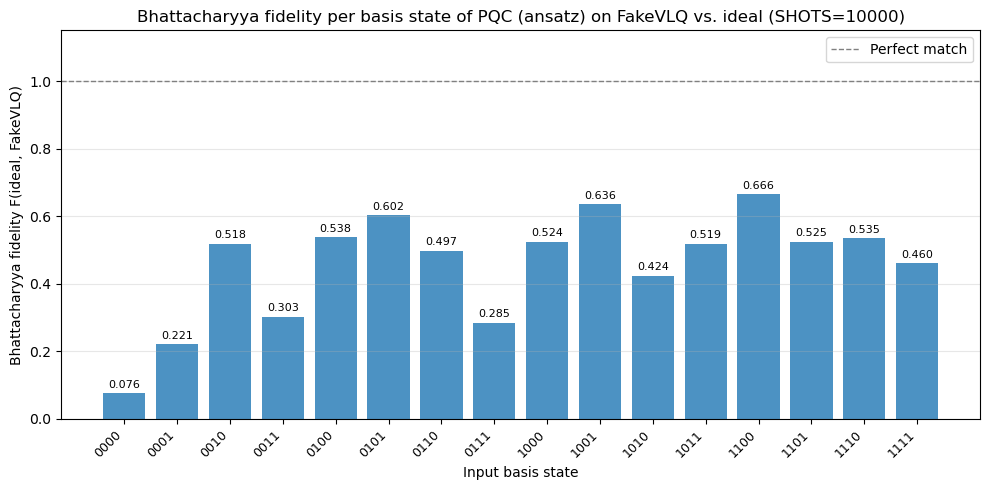

In [6]:
# --- Bhattacharyya fidelity visualisation ---
if bf_results:
    bitstrings_plot = [b for b in bitstrings if bf_results.get(b) is not None]
    bf_values = [bf_results[b] for b in bitstrings_plot]

    fig, ax = plt.subplots(figsize=(10, 5))
    x = range(len(bitstrings_plot))
    bars = ax.bar(x, bf_values, color='tab:blue', alpha=0.8)

    # Annotate each bar with its value
    for bar, val in zip(bars, bf_values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{val:.3f}", ha='center', va='bottom', fontsize=8)

    ax.set_xticks(list(x))
    ax.set_xticklabels(bitstrings_plot, rotation=45, ha='right', fontsize=9)
    ax.set_xlabel("Input basis state")
    ax.set_ylabel("Bhattacharyya fidelity F(ideal, FakeVLQ)")
    ax.set_title(f"Bhattacharyya fidelity per basis state of PQC (ansatz) on FakeVLQ vs. ideal (SHOTS={SHOTS})")
    ax.set_ylim(0, 1.15)
    ax.axhline(1.0, color='grey', linestyle='--', linewidth=1, label='Perfect match')
    ax.grid(True, axis='y', alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig("bf_per_basis_state_4N-PQC_on_FakeVLQ.png", dpi=300)
    plt.show()
